# Intercambiadores de calor: métodos LMTD y ε–NTU
### Dos problemas resueltos paso a paso — Transferencia de calor (pregrado)

**Objetivos de la sesión**

1. Plantear los balances de energía global de un intercambiador y reconocer cuál es la incógnita en cada tipo de problema.
2. Usar el método **ε–NTU** para un problema de *análisis de desempeño* (Problema 1: hallar $U$ a partir de mediciones).
3. Usar el método **ε–NTU** y verificarlo con **LMTD + factor de corrección $F$** en un problema de *dimensionamiento* (Problema 2: hallar el caudal de aceite y la longitud de tubos), incluyendo el cálculo de $h_i$ por convección forzada interna.
4. Discutir qué resistencia térmica controla el diseño y qué tan sensibles son los resultados a las hipótesis.

**Convenciones:** subíndice $h$ = fluido caliente, $c$ = fluido frío; $i$ = entrada, $o$ = salida. Propiedades tomadas de las tablas A.4 (aire), A.5 (aceite de motor) y A.6 (agua saturada) de Incropera, interpoladas linealmente.

Las ecuaciones $\varepsilon(\mathrm{NTU}, C_r)$ **no se leen en gráficas**: se invierten numéricamente con `scipy.optimize.brentq`.

## 1. Repaso de teoría

**Balances globales** (sin pérdidas al ambiente, sin cambio de fase):
$$q = \dot m_h c_{p,h}(T_{h,i}-T_{h,o}) = \dot m_c c_{p,c}(T_{c,o}-T_{c,i}),\qquad C_h=\dot m_h c_{p,h},\; C_c=\dot m_c c_{p,c}$$

**Ecuación de diseño (LMTD):**
$$q = U A\, F\, \Delta T_{lm,CF},\qquad \Delta T_{lm,CF}=\frac{\Delta T_1-\Delta T_2}{\ln(\Delta T_1/\Delta T_2)},\quad \Delta T_1=T_{h,i}-T_{c,o},\;\Delta T_2=T_{h,o}-T_{c,i}$$
($\Delta T_{lm}$ calculado **como si fuera contraflujo**; $F\le 1$ corrige para otras configuraciones).

**Método ε–NTU:**
$$C_{min}=\min(C_h,C_c),\quad C_r=\frac{C_{min}}{C_{max}},\quad q_{max}=C_{min}(T_{h,i}-T_{c,i}),\quad \varepsilon=\frac{q}{q_{max}},\quad \mathrm{NTU}=\frac{UA}{C_{min}}$$

| Configuración | $\varepsilon(\mathrm{NTU},C_r)$ |
|---|---|
| Flujo cruzado, ambos sin mezclar | $1-\exp\!\left[\dfrac{\mathrm{NTU}^{0.22}}{C_r}\left(e^{-C_r\,\mathrm{NTU}^{0.78}}-1\right)\right]$ |
| Flujo cruzado, $C_{max}$ mezclado | $\dfrac{1}{C_r}\left[1-e^{-C_r(1-e^{-\mathrm{NTU}})}\right]$ |
| Flujo cruzado, $C_{min}$ mezclado | $1-\exp\!\left[-\dfrac{1}{C_r}\left(1-e^{-C_r\mathrm{NTU}}\right)\right]$ |
| Carcasa y tubos, 1 paso por carcasa (2, 4, … pasos por tubos) | $2\left\{1+C_r+\sqrt{1+C_r^2}\,\dfrac{1+e^{-\mathrm{NTU}\sqrt{1+C_r^2}}}{1-e^{-\mathrm{NTU}\sqrt{1+C_r^2}}}\right\}^{-1}$ |
| Contraflujo | $\dfrac{1-e^{-\mathrm{NTU}(1-C_r)}}{1-C_r\,e^{-\mathrm{NTU}(1-C_r)}}$ |

**¿Cuál método usar?**
- Si se conocen las 4 temperaturas → LMTD es directo.
- Si faltan temperaturas de salida (análisis de desempeño) → ε–NTU evita iterar.
- En la práctica ambos son equivalentes: $F = \mathrm{NTU}_{CF}/\mathrm{NTU}$ para la misma $\varepsilon$ y $C_r$. Lo verificaremos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True, "grid.alpha": 0.3})
K = 273.15   # conversión °C -> K

## 2. Propiedades termofísicas (tablas de Incropera)

Se transcriben solo las columnas necesarias. `np.interp` hace la interpolación lineal, igual que se haría a mano con la tabla.

In [2]:
# --- Tabla A.4: aire a presión atmosférica (se usa como modelo de gases de escape) ---
T_air  = np.array([300, 350, 400, 450, 500, 550, 600, 650, 700])                 # K
cp_air = np.array([1.007, 1.009, 1.014, 1.021, 1.030, 1.040, 1.051, 1.063, 1.075]) * 1e3  # J/kg·K

# --- Tabla A.5: aceite de motor (sin usar) ---
T_oil  = np.array([360, 370, 380, 390, 400, 410, 420, 430])                       # K
cp_oil = np.array([2.161, 2.206, 2.250, 2.294, 2.337, 2.381, 2.427, 2.471]) * 1e3  # J/kg·K

# --- Tabla A.6: agua saturada (líquido) ---
T_w  = np.array([285, 290, 295, 300, 305, 310, 315, 320, 325, 330, 335, 340, 345, 350, 355, 360, 365, 370])
cp_w = np.array([4.189, 4.184, 4.181, 4.179, 4.178, 4.178, 4.179, 4.180, 4.182, 4.184,
                 4.186, 4.188, 4.191, 4.195, 4.199, 4.203, 4.209, 4.214]) * 1e3   # J/kg·K
mu_w = np.array([1225, 1080, 959, 855, 769, 695, 631, 577, 528, 489,
                 453, 420, 389, 365, 343, 324, 306, 289]) * 1e-6                  # N·s/m²
k_w  = np.array([590, 598, 606, 613, 620, 628, 634, 640, 645, 650,
                 656, 660, 664, 668, 671, 674, 677, 679]) * 1e-3                  # W/m·K
Pr_w = np.array([8.81, 7.56, 6.62, 5.83, 5.20, 4.62, 4.16, 3.77, 3.42, 3.15,
                 2.88, 2.66, 2.45, 2.29, 2.14, 2.02, 1.91, 1.80])

prop = lambda T, Tt, y: float(np.interp(T, Tt, y))

## 3. Funciones ε–NTU (directas e inversas)

Cada relación $\varepsilon(\mathrm{NTU})$ es monótona creciente, así que la inversa $\mathrm{NTU}(\varepsilon)$ se obtiene con `brentq` sin ambigüedad. Para carcasa y tubos también existe la inversa analítica; la usamos como verificación.

In [3]:
def eps_cruzado_sin_mezclar(NTU, Cr):
    return 1 - np.exp((NTU**0.22 / Cr) * (np.exp(-Cr * NTU**0.78) - 1))

def eps_cruzado_Cmax_mezclado(NTU, Cr):
    return (1 / Cr) * (1 - np.exp(-Cr * (1 - np.exp(-NTU))))

def eps_cruzado_Cmin_mezclado(NTU, Cr):
    return 1 - np.exp(-(1 / Cr) * (1 - np.exp(-Cr * NTU)))

def eps_carcasa_tubos_1(NTU, Cr):
    s = np.sqrt(1 + Cr**2)
    x = np.exp(-NTU * s)
    return 2 / (1 + Cr + s * (1 + x) / (1 - x))

def eps_contraflujo(NTU, Cr):
    if abs(1 - Cr) < 1e-12:
        return NTU / (1 + NTU)
    x = np.exp(-NTU * (1 - Cr))
    return (1 - x) / (1 - Cr * x)

def NTU_desde_eps(eps_fun, eps, Cr, NTU_max=50.0):
    '''Invierte eps = eps_fun(NTU, Cr) numéricamente.'''
    return brentq(lambda N: eps_fun(N, Cr) - eps, 1e-9, NTU_max)

def NTU_carcasa_tubos_analitico(eps, Cr):
    s = np.sqrt(1 + Cr**2)
    E = (2 / eps - (1 + Cr)) / s
    return -np.log((E - 1) / (E + 1)) / s

def LMTD(dT1, dT2):
    return (dT1 - dT2) / np.log(dT1 / dT2)

---
## 4. Problema 1 — Intercambiador de flujo cruzado con tubos aletados

> Un intercambiador de flujo cruzado con tubos aletados usa los gases de escape de una turbina de gas para calentar agua presurizada. En un prototipo de área $A=10\ \mathrm{m^2}$ se mide: $\dot m_h=2$ kg/s, $T_{h,i}=325$ °C, $\dot m_c=0.5$ kg/s, $T_{c,i}=25$ °C y $T_{c,o}=150$ °C. ¿Cuál es el coeficiente global $U$?

**Tipo de problema:** *análisis* — se conoce el desempeño medido y se busca $U$. Falta $T_{h,o}$.

**Hipótesis**
1. Estado estacionario; pérdidas al ambiente despreciables; cambios de energía cinética y potencial despreciables.
2. Gases de escape con propiedades de **aire** (tabla A.4).
3. Agua presurizada: permanece líquida → propiedades de líquido saturado (tabla A.6), $c_p$ casi independiente de la presión.
4. Configuración: **flujo cruzado, ambos fluidos sin mezclar** (las aletas separan el gas en canales; el agua va dentro de tubos). Discutiremos esta hipótesis al final.
5. Propiedades constantes evaluadas a la temperatura media de cada corriente.

### 4.1 Balance del lado frío → $q$

In [4]:
# Datos
A1   = 10.0      # m²
mh1  = 2.0       # kg/s  (gases)
Thi1 = 325.0     # °C
mc1  = 0.5       # kg/s  (agua)
Tci1 = 25.0      # °C
Tco1 = 150.0     # °C

Tc_media = 0.5 * (Tci1 + Tco1)
cpc1 = prop(Tc_media + K, T_w, cp_w)
Cc1  = mc1 * cpc1
q1   = Cc1 * (Tco1 - Tci1)

print(f"T media agua    = {Tc_media:.1f} °C  ({Tc_media+K:.0f} K)")
print(f"cp,c            = {cpc1:.0f} J/kg·K")
print(f"C_c             = {Cc1:.0f} W/K")
print(f"q               = {q1/1e3:.1f} kW")

T media agua    = 87.5 °C  (361 K)
cp,c            = 4204 J/kg·K
C_c             = 2102 W/K
q               = 262.7 kW


### 4.2 Balance del lado caliente → $T_{h,o}$ (iteración corta)

$c_{p,h}$ depende de la temperatura media del gas, que depende de $T_{h,o}$, que depende de $c_{p,h}$. Se itera por sustitución sucesiva (converge en 2–3 pasos porque $c_p$ del aire varía poco).

In [5]:
Tho1 = Thi1 - 100.0          # suposición inicial
print(" it   T_h,o [°C]   cp,h [J/kg·K]")
for it in range(10):
    cph1 = prop(0.5 * (Thi1 + Tho1) + K, T_air, cp_air)
    Tho_nuevo = Thi1 - q1 / (mh1 * cph1)
    print(f"{it:3d}   {Tho_nuevo:9.2f}   {cph1:10.1f}")
    if abs(Tho_nuevo - Tho1) < 1e-3:
        break
    Tho1 = Tho_nuevo
Tho1 = Tho_nuevo
Ch1 = mh1 * cph1
print(f"\nT_h,o = {Tho1:.1f} °C,   C_h = {Ch1:.0f} W/K")

 it   T_h,o [°C]   cp,h [J/kg·K]
  0      198.64       1039.6
  1      198.32       1037.0
  2      198.31       1037.0
  3      198.31       1037.0

T_h,o = 198.3 °C,   C_h = 2074 W/K


### 4.3 Efectividad y NTU

Observe que $C_h\approx C_c$ → $C_r\approx 1$. Este es el caso en que el intercambiador de flujo cruzado es *menos* efectivo relativo al contraflujo, así que la hipótesis de configuración importa.

In [6]:
Cmin1, Cmax1 = min(Ch1, Cc1), max(Ch1, Cc1)
Cr1   = Cmin1 / Cmax1
qmax1 = Cmin1 * (Thi1 - Tci1)
eps1  = q1 / qmax1

NTU1  = NTU_desde_eps(eps_cruzado_sin_mezclar, eps1, Cr1)
U1    = NTU1 * Cmin1 / A1

print(f"C_min = {Cmin1:.0f} W/K  ({'gas' if Cmin1 == Ch1 else 'agua'}),  C_r = {Cr1:.3f}")
print(f"q_max = {qmax1/1e3:.1f} kW")
print(f"ε     = {eps1:.4f}")
print(f"NTU   = {NTU1:.4f}")
print(f"\n>>> U = {U1:.1f} W/m²·K")

C_min = 2074 W/K  (gas),  C_r = 0.987
q_max = 622.2 kW
ε     = 0.4223
NTU   = 0.8100

>>> U = 168.0 W/m²·K


### 4.4 Verificación con LMTD y factor $F$

Con las cuatro temperaturas ya conocidas se puede aplicar LMTD. El factor $F$ implícito es $F=\mathrm{NTU}_{CF}/\mathrm{NTU}$ (mismo $\varepsilon$ y $C_r$). Si todo es consistente, $UAF\,\Delta T_{lm,CF}$ debe reproducir $q$ exactamente.

In [7]:
dT1 = Thi1 - Tco1
dT2 = Tho1 - Tci1
dTlm1 = LMTD(dT1, dT2)
NTU_cf1 = NTU_desde_eps(eps_contraflujo, eps1, Cr1)
F1 = NTU_cf1 / NTU1

print(f"ΔT1 = {dT1:.1f} K,  ΔT2 = {dT2:.1f} K,  ΔT_lm,CF = {dTlm1:.2f} K")
print(f"NTU (contraflujo, mismo ε) = {NTU_cf1:.4f}")
print(f"F = NTU_CF / NTU = {F1:.4f}")
print(f"q por LMTD = U·A·F·ΔT_lm = {U1*A1*F1*dTlm1/1e3:.2f} kW   (balance: {q1/1e3:.2f} kW)")

ΔT1 = 175.0 K,  ΔT2 = 173.3 K,  ΔT_lm,CF = 174.16 K
NTU (contraflujo, mismo ε) = 0.7274
F = NTU_CF / NTU = 0.8980
q por LMTD = U·A·F·ΔT_lm = 262.74 kW   (balance: 262.74 kW)


### 4.5 Punto de operación en el diagrama ε–NTU

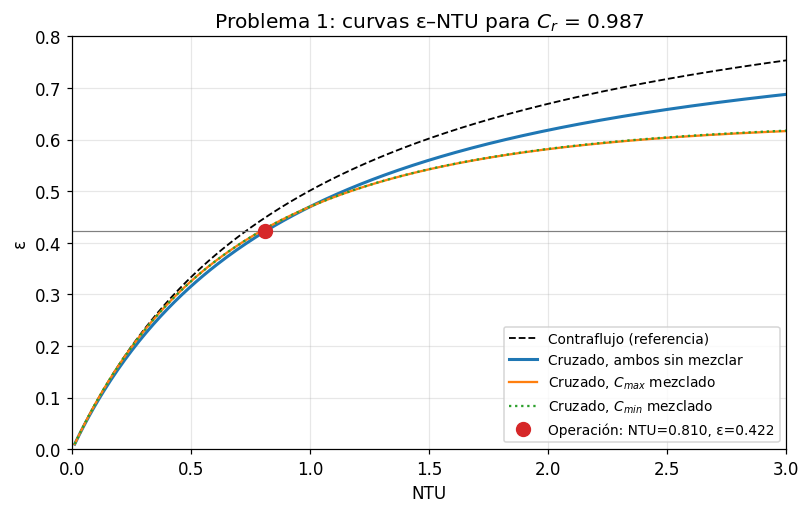

In [8]:
N = np.linspace(0.01, 3, 300)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(N, [eps_contraflujo(n, Cr1) for n in N], 'k--', lw=1.2, label='Contraflujo (referencia)')
ax.plot(N, eps_cruzado_sin_mezclar(N, Cr1), 'C0', lw=2, label='Cruzado, ambos sin mezclar')
ax.plot(N, eps_cruzado_Cmax_mezclado(N, Cr1), 'C1', lw=1.5, label='Cruzado, $C_{max}$ mezclado')
ax.plot(N, eps_cruzado_Cmin_mezclado(N, Cr1), 'C2', lw=1.5, ls=':', label='Cruzado, $C_{min}$ mezclado')
ax.axhline(eps1, color='gray', lw=0.8)
ax.plot(NTU1, eps1, 'o', color='C3', ms=9, zorder=5, label=f'Operación: NTU={NTU1:.3f}, ε={eps1:.3f}')
ax.set_xlabel('NTU'); ax.set_ylabel('ε')
ax.set_title(f'Problema 1: curvas ε–NTU para $C_r$ = {Cr1:.3f}')
ax.set_xlim(0, 3); ax.set_ylim(0, 0.8); ax.legend(loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()

### 4.6 ¿Qué tanto importa la hipótesis de mezcla?

El enunciado no dice explícitamente si los fluidos están mezclados. Calculamos $U$ con las tres variantes de flujo cruzado y con contraflujo (cota inferior de $U$: el contraflujo es la configuración más efectiva, así que requiere el menor $UA$ para la misma $\varepsilon$).

In [9]:
casos = {
    'Cruzado, ambos sin mezclar':  eps_cruzado_sin_mezclar,
    'Cruzado, C_max (agua) mezclado': eps_cruzado_Cmax_mezclado,
    'Cruzado, C_min (gas) mezclado':  eps_cruzado_Cmin_mezclado,
    'Contraflujo ideal (cota)':      eps_contraflujo,
}
print(f"{'Configuración':34s} {'NTU':>7s} {'U [W/m²K]':>11s} {'Δ vs base':>10s}")
for nombre, f in casos.items():
    n = NTU_desde_eps(f, eps1, Cr1)
    u = n * Cmin1 / A1
    print(f"{nombre:34s} {n:7.4f} {u:11.1f} {100*(u/U1-1):9.1f} %")

Configuración                          NTU   U [W/m²K]  Δ vs base
Cruzado, ambos sin mezclar          0.8100       168.0       0.0 %
Cruzado, C_max (agua) mezclado      0.7902       163.9      -2.4 %
Cruzado, C_min (gas) mezclado       0.7900       163.8      -2.5 %
Contraflujo ideal (cota)            0.7274       150.9     -10.2 %


**Lectura:** con $\varepsilon\approx 0.42$ el intercambiador trabaja en la zona baja de NTU, donde todas las curvas están juntas; por eso la hipótesis de mezcla cambia $U$ solo en unos pocos por ciento. Note además que las dos variantes "mezcladas" casi coinciden: para $C_r=1$ sus fórmulas son idénticas, y aquí $C_r=0.987$. A efectividades altas (NTU > 2) las diferencias se vuelven grandes — ahí la configuración sí importa para el diseño.

**Pregunta para clase:** ¿por qué tiene sentido que la cota de contraflujo dé el *menor* $U$?

---
## 5. Problema 2 — Intercambiador de carcasa y tubos (dimensionamiento)

> Se debe diseñar un intercambiador de carcasa y tubos para calentar $2.5$ kg/s de agua de 15 a 85 °C con aceite de motor caliente disponible a 160 °C, que circula por la carcasa con $h_o=400\ \mathrm{W/m^2K}$. Diez tubos de pared delgada, $D=25$ mm, con ocho pasos por la carcasa. Si el aceite sale a 100 °C, ¿cuál es su caudal? ¿Qué longitud deben tener los tubos?

**Tipo de problema:** *diseño* — se conocen las cuatro temperaturas, se busca $\dot m_h$ y el área (longitud).

**Hipótesis**
1. Estado estacionario, pérdidas despreciables, pared delgada (resistencia de la pared despreciable), sin ensuciamiento.
2. **Un paso por la carcasa y 8 pasos por los tubos** (múltiplo par → vale la relación de carcasa y tubos con 1 paso por carcasa).
3. Flujo interno **completamente desarrollado** en toda la longitud (se verificará $L/D$).
4. Propiedades constantes evaluadas a la temperatura media de cada corriente.
5. El agua se reparte por igual entre los 10 tubos.

### 5.1 Balances de energía → $q$ y $\dot m_h$

In [10]:
# Datos
mc2  = 2.5       # kg/s  (agua, lado tubos)
Tci2, Tco2 = 15.0, 85.0
Thi2, Tho2 = 160.0, 100.0   # aceite, lado carcasa
ho2  = 400.0     # W/m²·K
Nt   = 10        # número de tubos
D2   = 0.025     # m
Npasos = 8

# Agua a la temperatura media
Tmc2 = 0.5 * (Tci2 + Tco2) + K
cpc2 = prop(Tmc2, T_w, cp_w)
q2   = mc2 * cpc2 * (Tco2 - Tci2)

# Aceite a la temperatura media
Tmh2 = 0.5 * (Thi2 + Tho2) + K
cph2 = prop(Tmh2, T_oil, cp_oil)
mh2  = q2 / (cph2 * (Thi2 - Tho2))

print(f"Agua:   T media = {Tmc2:.0f} K,  cp = {cpc2:.0f} J/kg·K")
print(f"Aceite: T media = {Tmh2:.0f} K,  cp = {cph2:.0f} J/kg·K")
print(f"q = {q2/1e3:.1f} kW")
print(f"\n>>> Caudal de aceite: m_h = {mh2:.2f} kg/s")

Agua:   T media = 323 K,  cp = 4181 J/kg·K
Aceite: T media = 403 K,  cp = 2351 J/kg·K
q = 731.7 kW

>>> Caudal de aceite: m_h = 5.19 kg/s


### 5.2 Coeficiente interno $h_i$ (agua en los tubos)

Caudal por tubo: $\dot m_1=\dot m_c/N_t$. Con $\mathrm{Re}_D = 4\dot m_1/(\pi D\mu)$, si el flujo es turbulento se usa **Dittus–Boelter** con $n=0.4$ (el agua se calienta):
$$\mathrm{Nu}_D = 0.023\,\mathrm{Re}_D^{4/5}\,\mathrm{Pr}^{0.4},\qquad h_i=\mathrm{Nu}_D\,k/D$$
Como verificación se compara con **Gnielinski** (más exacta, error típico < 10 %).

In [11]:
mu2 = prop(Tmc2, T_w, mu_w)
k2  = prop(Tmc2, T_w, k_w)
Pr2 = prop(Tmc2, T_w, Pr_w)

m1  = mc2 / Nt
Re2 = 4 * m1 / (np.pi * D2 * mu2)

Nu_DB = 0.023 * Re2**0.8 * Pr2**0.4
f_G   = (0.790 * np.log(Re2) - 1.64)**-2
Nu_G  = (f_G / 8) * (Re2 - 1000) * Pr2 / (1 + 12.7 * np.sqrt(f_G / 8) * (Pr2**(2/3) - 1))

hi2 = Nu_DB * k2 / D2
print(f"μ = {mu2*1e6:.0f}e-6 N·s/m²,  k = {k2:.3f} W/m·K,  Pr = {Pr2:.2f}")
print(f"Caudal por tubo = {m1:.3f} kg/s")
print(f"Re_D = {Re2:,.0f}   -> {'turbulento' if Re2 > 1e4 else 'REVISAR régimen'}")
print(f"Validez Dittus–Boelter: Re > 1e4 {'✓' if Re2 > 1e4 else '✗'},  0.6 < Pr < 160 {'✓' if 0.6 < Pr2 < 160 else '✗'}")
print(f"\nNu (Dittus–Boelter) = {Nu_DB:.1f}  -> h_i = {hi2:.0f} W/m²·K")
print(f"Nu (Gnielinski)     = {Nu_G:.1f}  -> h_i = {Nu_G*k2/D2:.0f} W/m²·K  (diferencia {100*(Nu_G/Nu_DB-1):+.1f} %)")

μ = 546e-6 N·s/m²,  k = 0.643 W/m·K,  Pr = 3.55
Caudal por tubo = 0.250 kg/s
Re_D = 23,314   -> turbulento
Validez Dittus–Boelter: Re > 1e4 ✓,  0.6 < Pr < 160 ✓

Nu (Dittus–Boelter) = 119.1  -> h_i = 3064 W/m²·K
Nu (Gnielinski)     = 128.1  -> h_i = 3294 W/m²·K  (diferencia +7.5 %)


### 5.3 Coeficiente global $U$ y análisis de resistencias

Pared delgada → $A_i\approx A_o$ y
$$\frac{1}{U}=\frac{1}{h_i}+\frac{1}{h_o}$$

In [12]:
U2 = 1 / (1 / hi2 + 1 / ho2)
R_i, R_o = 1 / hi2, 1 / ho2
print(f"U = {U2:.1f} W/m²·K")
print(f"Resistencia lado agua   : {100*R_i/(R_i+R_o):5.1f} %")
print(f"Resistencia lado aceite : {100*R_o/(R_i+R_o):5.1f} %")

U = 353.8 W/m²·K
Resistencia lado agua   :  11.5 %
Resistencia lado aceite :  88.5 %


El lado del aceite domina (~88 % de la resistencia). **Consecuencia de diseño:** mejorar $h_i$ (más velocidad del agua) casi no ayuda; lo que importa es $h_o$ (deflectores en la carcasa, aletas externas).

### 5.4 Área requerida por ε–NTU

In [13]:
Cc2 = mc2 * cpc2
Ch2 = mh2 * cph2
Cmin2, Cmax2 = min(Cc2, Ch2), max(Cc2, Ch2)
Cr2   = Cmin2 / Cmax2
qmax2 = Cmin2 * (Thi2 - Tci2)
eps2  = q2 / qmax2

NTU2_num = NTU_desde_eps(eps_carcasa_tubos_1, eps2, Cr2)
NTU2_ana = NTU_carcasa_tubos_analitico(eps2, Cr2)
A2 = NTU2_num * Cmin2 / U2

print(f"C_c = {Cc2:.0f} W/K,  C_h = {Ch2:.0f} W/K  -> C_min = {'agua' if Cmin2 == Cc2 else 'aceite'}, C_r = {Cr2:.3f}")
print(f"ε = {eps2:.4f}")
print(f"NTU (brentq) = {NTU2_num:.5f}   NTU (analítico) = {NTU2_ana:.5f}")
print(f"A = NTU·C_min/U = {A2:.2f} m²")

C_c = 10453 W/K,  C_h = 12195 W/K  -> C_min = agua, C_r = 0.857
ε = 0.4828
NTU (brentq) = 0.99734   NTU (analítico) = 0.99734
A = NTU·C_min/U = 29.47 m²


### 5.5 Verificación por LMTD con factor $F$ (fórmula cerrada, 1 paso por carcasa)

Con el fluido de los tubos (agua, $t$) y el de la carcasa (aceite, $T$):
$$P=\frac{t_o-t_i}{T_i-t_i},\qquad R=\frac{T_i-T_o}{t_o-t_i}$$
$$F=\frac{\sqrt{R^2+1}}{R-1}\;\frac{\ln\!\left[\dfrac{1-P}{1-PR}\right]}{\ln\!\left[\dfrac{2-P\left(R+1-\sqrt{R^2+1}\right)}{2-P\left(R+1+\sqrt{R^2+1}\right)}\right]}$$

In [14]:
P = (Tco2 - Tci2) / (Thi2 - Tci2)
R = (Thi2 - Tho2) / (Tco2 - Tci2)
s = np.sqrt(R**2 + 1)
F2 = (s / (R - 1)) * np.log((1 - P) / (1 - P * R)) / \
     np.log((2 - P * (R + 1 - s)) / (2 - P * (R + 1 + s)))

dTlm2 = LMTD(Thi2 - Tco2, Tho2 - Tci2)
A2_lmtd = q2 / (U2 * F2 * dTlm2)

print(f"P = {P:.4f},  R = {R:.4f},  F = {F2:.4f}")
print(f"ΔT_lm,CF = {dTlm2:.2f} K")
print(f"A (LMTD) = {A2_lmtd:.3f} m²    A (ε–NTU) = {A2:.3f} m²   -> diferencia {100*abs(A2_lmtd/A2-1):.2e} %")

P = 0.4828,  R = 0.8571,  F = 0.8785
ΔT_lm,CF = 79.90 K
A (LMTD) = 29.466 m²    A (ε–NTU) = 29.466 m²   -> diferencia 1.11e-13 %


### 5.6 Longitud de los tubos

$A = N_t\,\pi D\,L$, donde $L$ es la **longitud total de cada tubo** (sumando sus 8 pasos). La longitud de la carcasa es aproximadamente $L/N_{pasos}$.

In [15]:
L2 = A2 / (Nt * np.pi * D2)
print(f">>> Longitud total de cada tubo: L = {L2:.1f} m")
print(f"    Longitud por paso (≈ longitud de la carcasa): {L2/Npasos:.2f} m")
print(f"    L/D = {L2/D2:.0f}  (>> 10: la hipótesis de flujo desarrollado es razonable)")

>>> Longitud total de cada tubo: L = 37.5 m
    Longitud por paso (≈ longitud de la carcasa): 4.69 m
    L/D = 1501  (>> 10: la hipótesis de flujo desarrollado es razonable)


### 5.7 Sensibilidad del diseño

**(a)** ¿Cómo cambia la longitud requerida si se mejora $h_o$ (lado aceite) o $h_i$ (lado agua)?
**(b)** ¿Cuánto se pierde respecto a un contraflujo ideal? (efecto del factor $F$)

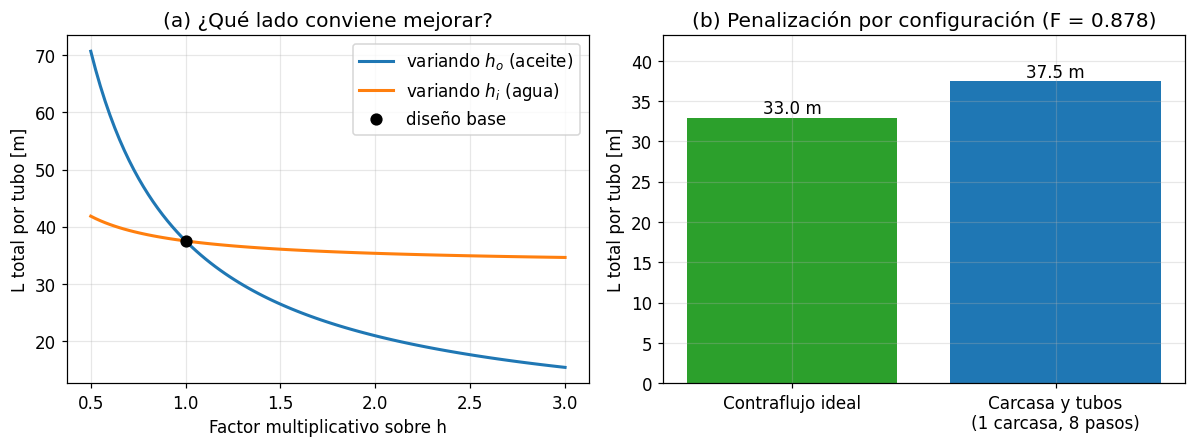

Duplicar h_o reduce L de 37.5 a 20.9 m;  duplicar h_i solo a 35.4 m


In [16]:
def longitud(hi, ho):
    U = 1 / (1 / hi + 1 / ho)
    return NTU2_num * Cmin2 / U / (Nt * np.pi * D2)

factor = np.linspace(0.5, 3, 100)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

axs[0].plot(factor, [longitud(hi2, ho2 * f) for f in factor], 'C0', lw=2, label='variando $h_o$ (aceite)')
axs[0].plot(factor, [longitud(hi2 * f, ho2) for f in factor], 'C1', lw=2, label='variando $h_i$ (agua)')
axs[0].plot(1, L2, 'ko', ms=7, label='diseño base')
axs[0].set_xlabel('Factor multiplicativo sobre h'); axs[0].set_ylabel('L total por tubo [m]')
axs[0].set_title('(a) ¿Qué lado conviene mejorar?'); axs[0].legend()

NTU_cf2 = NTU_desde_eps(eps_contraflujo, eps2, Cr2)
etiquetas = ['Contraflujo ideal', 'Carcasa y tubos\n(1 carcasa, 8 pasos)']
Ls = [NTU_cf2 * Cmin2 / U2 / (Nt * np.pi * D2), L2]
b = axs[1].bar(etiquetas, Ls, color=['C2', 'C0'])
axs[1].bar_label(b, fmt='%.1f m')
axs[1].set_ylabel('L total por tubo [m]'); axs[1].set_ylim(0, 1.15 * max(Ls))
axs[1].set_title(f'(b) Penalización por configuración (F = {F2:.3f})')
plt.tight_layout(); plt.show()

print(f"Duplicar h_o reduce L de {L2:.1f} a {longitud(hi2, 2*ho2):.1f} m;  duplicar h_i solo a {longitud(2*hi2, ho2):.1f} m")

**Observación:** el número de pasos por los tubos (2, 4, 8…) **no cambia la longitud total** requerida en este modelo: la relación ε–NTU es la misma para cualquier número par de pasos con un paso por carcasa, y el caudal por tubo (y por tanto $h_i$) tampoco cambia. Los pasos solo "doblan" el tubo para que la carcasa mida ~4.7 m en lugar de ~38 m.

---
## 6. Resumen de resultados

In [17]:
print("PROBLEMA 1 — flujo cruzado (ambos sin mezclar)")
print(f"  q = {q1/1e3:.1f} kW,  T_h,o = {Tho1:.1f} °C,  ε = {eps1:.3f},  NTU = {NTU1:.3f}")
print(f"  U = {U1:.0f} W/m²·K")
print()
print("PROBLEMA 2 — carcasa y tubos (1 carcasa, 8 pasos)")
print(f"  q = {q2/1e3:.1f} kW,  m_aceite = {mh2:.2f} kg/s")
print(f"  Re = {Re2:,.0f},  h_i = {hi2:.0f} W/m²·K,  U = {U2:.0f} W/m²·K")
print(f"  ε = {eps2:.3f},  NTU = {NTU2_num:.3f},  F = {F2:.3f},  A = {A2:.1f} m²")
print(f"  L = {L2:.1f} m por tubo  ({L2/Npasos:.2f} m por paso)")

PROBLEMA 1 — flujo cruzado (ambos sin mezclar)
  q = 262.7 kW,  T_h,o = 198.3 °C,  ε = 0.422,  NTU = 0.810
  U = 168 W/m²·K

PROBLEMA 2 — carcasa y tubos (1 carcasa, 8 pasos)
  q = 731.7 kW,  m_aceite = 5.19 kg/s
  Re = 23,314,  h_i = 3064 W/m²·K,  U = 354 W/m²·K
  ε = 0.483,  NTU = 0.997,  F = 0.878,  A = 29.5 m²
  L = 37.5 m por tubo  (4.69 m por paso)


**Ideas clave para cerrar la clase**

1. En el Problema 1 no se conocían todas las temperaturas al inicio; el balance de energía las completa y ε–NTU entrega $U$ sin iterar sobre $\Delta T_{lm}$.
2. LMTD y ε–NTU son **el mismo modelo** escrito de dos formas; $F = \mathrm{NTU}_{CF}/\mathrm{NTU}$.
3. Con $C_r\approx1$ y $\varepsilon$ moderada, la configuración (mezclado/sin mezclar) influye poco; su peso crece con NTU.
4. En el Problema 2 el lado del aceite controla la transferencia: el diseño se mejora actuando sobre $h_o$.
5. Siempre verificar las correlaciones usadas (régimen, rango de Pr, $L/D$).

---
## 7. Ejercicios propuestos

1. **(P1) Operación fuera de diseño.** Con el $U$ obtenido, calcule las temperaturas de salida si el caudal de agua se duplica ($\dot m_c=1$ kg/s) manteniendo lo demás. *Pista:* ahora $C_{min}$ cambia de fluido; suponga $U$ constante (y luego discuta si eso es razonable).
2. **(P1) Sensibilidad a la medición.** Si el termopar de salida del agua tiene una incertidumbre de ±3 °C, ¿qué rango de $U$ resulta? ¿Qué medición es más crítica para estimar $U$?
3. **(P2) Aceite más frío.** Si el aceite debe salir a 90 °C, recalcule $\dot m_h$ y $L$. ¿Por qué crece tanto la longitud?
4. **(P2) Ensuciamiento.** Agregue resistencias de ensuciamiento $R''_{f,i}=0.0002$ y $R''_{f,o}=0.0009\ \mathrm{m^2K/W}$ (valores típicos agua/aceite). ¿Cuánto aumenta $L$?
5. **(P2) Dos pasos por carcasa.** Deduzca/implemente $\varepsilon$ para $n$ carcasas en serie y compare la longitud con el caso de una carcasa.
6. **(P2) Diámetro del tubo.** Repita el diseño con $D=20$ mm y $D=32$ mm. ¿Cómo cambian $\mathrm{Re}$, $h_i$, $U$ y $L$? ¿Vale la pena cambiar el diámetro dado el análisis de resistencias?